# Scratch — ESM HDF5 file `EMSC-20100930_0000013__VRI__00.h5`

A playground for one of the six ESM files the new converter refuses to resolve (see nb 042 / nb 043). The file is
opened read-only from the HSU share (`cfg["raw_data"]["esm_hdf5_folder"]`), so the share must be reachable from the
kernel. **Nothing here writes anywhere.**

**File structure** (ASDF 1.0.3, i.e. HDF5 with the ASDF layout):

```
/                          attrs: file_format = "ASDF", file_format_version = "1.0.3"
├── AuxiliaryData/         empty
├── Provenance/            empty
└── Waveforms/
    ├── EU.VRI/            network EU, station VRI
    │   ├── EU.VRI.00.HNE__2010-09-30T05:30:29__2010-09-30T05:34:33__00_hne_..._acc_mp   (48798,) float64
    │   ├── EU.VRI.00.HNN__...                                                            (48798,)
    │   └── EU.VRI.00.HNZ__...                                                            (48798,)
    └── RO.VRI/            network RO, station VRI
        ├── RO.VRI..HNE__2010-09-30T05:31:29__2010-09-30T05:32:49___hne_..._acc_mp        (16000,) float64
        ├── RO.VRI..HNN__...                                                              (16000,)
        └── RO.VRI..HNZ__...                                                              (16000,)
```

* Each dataset is one channel, keyed by its SEED id `NET.STA.LOC.CHA`, then `__start__end__tag`. The waveform is
  acceleration in **cm/s²** (the converter divides by 100·g). Per-dataset attributes: `event_id`,
  `sampling_rate` (200 Hz for all six), and `starttime` (ns since 1970).
* **Two recordings of the same station and event, from two networks.**
  * `EU.VRI`: location `00`, 244 s long, starting 05:30:29.
  * `RO.VRI`: location `""` (blank), 80 s long, starting 60 s later (05:31:29).

  Both are `HN` strong-motion accelerometers.
* **Why the converter stops here:** the file name says location `00`, and `""` and `00` both normalise to `00`. So two
  instruments pass the location rule, and neither the rule nor the channel map can choose between them.

The cells below: open the file, print the tree, tabulate the datasets, plot the traces on a common time axis, and
compare their spectra with the DB rows of this event/station.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from phd_project.config.config import load_config

pd.set_option("display.width", 200)

cfg = load_config()
FP = Path(cfg["raw_data"]["esm_hdf5_folder"]) / "EMSC-20100930_0000013__VRI__00.h5"
EVENT_ID, STATION = "EMSC-20100930_0000013", "VRI"
G0 = 9.80665

# Opened read-only and left open, so it can be explored interactively below.
# Run h5.close() when done (or restart the kernel).
h5 = h5py.File(FP, "r")
print(FP.name, "| file attrs:", {k: v.decode() if isinstance(v, bytes) else v for k, v in h5.attrs.items()})

EMSC-20100930_0000013__VRI__00.h5 | file attrs: {'file_format': 'ASDF', 'file_format_version': '1.0.3'}


## 1. The full tree

In [2]:
def print_tree(obj, indent=0):
    """Print every group and dataset below `obj`, with shapes and attributes."""
    for name, item in obj.items():
        pad = "    " * indent
        if isinstance(item, h5py.Group):
            print(f"{pad}{name}/  ({len(item)} item(s))")
            print_tree(item, indent + 1)
        else:
            attrs = {k: (v.decode()[-40:] if isinstance(v, bytes) else v) for k, v in item.attrs.items()}
            print(f"{pad}{name}  shape={item.shape} dtype={item.dtype}")
            print(f"{pad}    attrs: {attrs}")

print_tree(h5)

AuxiliaryData/  (0 item(s))
Provenance/  (0 item(s))
Waveforms/  (2 item(s))
    EU.VRI/  (3 item(s))
        EU.VRI.00.HNE__2010-09-30T05:30:29__2010-09-30T05:34:33__00_hne_emsc_20100930_0000013_acc_mp  shape=(48798,) dtype=float64
            attrs: {'event_id': 't/1/query?event_id=EMSC-20100930_0000013', 'sampling_rate': np.float64(200.0), 'starttime': np.int64(1285824629968000000)}
        EU.VRI.00.HNN__2010-09-30T05:30:29__2010-09-30T05:34:33__00_hnn_emsc_20100930_0000013_acc_mp  shape=(48798,) dtype=float64
            attrs: {'event_id': 't/1/query?event_id=EMSC-20100930_0000013', 'sampling_rate': np.float64(200.0), 'starttime': np.int64(1285824629968000000)}
        EU.VRI.00.HNZ__2010-09-30T05:30:29__2010-09-30T05:34:33__00_hnz_emsc_20100930_0000013_acc_mp  shape=(48798,) dtype=float64
            attrs: {'event_id': 't/1/query?event_id=EMSC-20100930_0000013', 'sampling_rate': np.float64(200.0), 'starttime': np.int64(1285824629968000000)}
    RO.VRI/  (3 item(s))
        RO.V

## 2. The datasets as a table

The SEED id is parsed from the key; `PGA` is in g (cm/s² ÷ 100·g).

In [3]:
rows, traces = [], {}
for group in h5["Waveforms"]:
    for key, ds in h5["Waveforms"][group].items():
        seed_id, start, end, tag = key.split("__", 3)
        net, sta, loc, cha = seed_id.split(".")
        fs = float(ds.attrs["sampling_rate"])
        acc_g = np.asarray(ds[()], dtype=float) / (100.0 * G0)     # cm/s^2 -> g
        label = f"{net}.{sta}.{loc or '--'}.{cha}"
        traces[label] = {"acc_g": acc_g, "dt": 1 / fs,
                         "t0": np.datetime64(int(ds.attrs["starttime"]), "ns")}
        rows.append({"label": label, "group": group, "net": net, "sta": sta,
                     "loc": repr(loc), "cha": cha, "start": start, "end": end,
                     "n_samples": ds.shape[0], "fs_Hz": fs, "duration_s": ds.shape[0] / fs,
                     "PGA_g": np.abs(acc_g).max()})
datasets = pd.DataFrame(rows).set_index("label")
datasets

,group,net,sta,loc,cha,start,end,n_samples,fs_Hz,duration_s,PGA_g
label,,,,,,,,,,,
EU.VRI.00.HNE,EU.VRI,EU,VRI,'00',HNE,2010-09-30T05:30:29,2010-09-30T05:34:33,48798,200.0,243.99,0.001199
EU.VRI.00.HNN,EU.VRI,EU,VRI,'00',HNN,2010-09-30T05:30:29,2010-09-30T05:34:33,48798,200.0,243.99,0.000744
EU.VRI.00.HNZ,EU.VRI,EU,VRI,'00',HNZ,2010-09-30T05:30:29,2010-09-30T05:34:33,48798,200.0,243.99,0.001897
RO.VRI.--.HNE,RO.VRI,RO,VRI,'',HNE,2010-09-30T05:31:29,2010-09-30T05:32:49,16000,200.0,80.00,0.001199
RO.VRI.--.HNN,RO.VRI,RO,VRI,'',HNN,2010-09-30T05:31:29,2010-09-30T05:32:49,16000,200.0,80.00,0.000743
RO.VRI.--.HNZ,RO.VRI,RO,VRI,'',HNZ,2010-09-30T05:31:29,2010-09-30T05:32:49,16000,200.0,80.00,0.001917


## 3. Traces on a common time axis

Time is measured from the earliest `starttime` in the file, so the two networks' records line up.

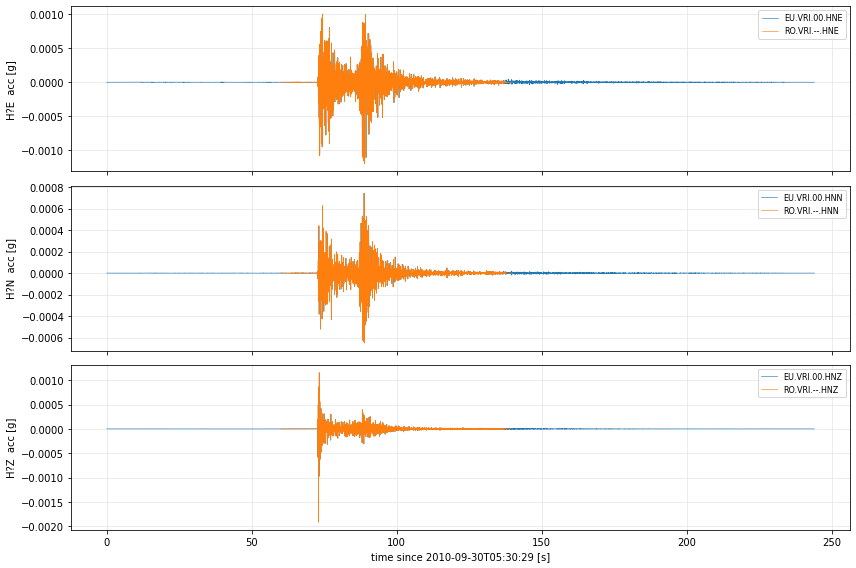

In [4]:
t_ref = min(tr["t0"] for tr in traces.values())
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, comp in zip(axes, ["E", "N", "Z"]):
    for label, tr in traces.items():
        if label.endswith(comp):
            t = (tr["t0"] - t_ref) / np.timedelta64(1, "s") + np.arange(len(tr["acc_g"])) * tr["dt"]
            ax.plot(t, tr["acc_g"], lw=0.6, label=label)
    ax.set_ylabel(f"H?{comp}  acc [g]")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, color="0.9")
axes[-1].set_xlabel(f"time since {np.datetime_as_string(t_ref, unit='s')} [s]")
fig.tight_layout()

## 4. Which recording is the DB record?

The PSA (5 %) of every horizontal channel, computed with the TH pipeline's routine, scored (MSLE up to
`max_usable_T`) against every DB row of this event/station. The lowest MSLE per DB row says which network's
recording the DB spectrum was computed from.

In [5]:
from phd_project.scripts import timehistory_spectra_verification as tsv
from phd_project.scripts.compute_record_spectra import psa_spectrum

db = tsv.load_db_spectra()                     # ~15 s: reads the 120 MB combined DB
periods = tsv._compared_periods(tsv.load_th_spectra(), db)
db_rows = db[(db["event_id"] == EVENT_ID) & (db["station_code"] == STATION)]
display(db_rows[["tag", "component", "mag", "rjb", "vs30", "max_usable_T"]])

psa = {lab: psa_spectrum(tr["acc_g"], tr["dt"], periods, 0.05)
       for lab, tr in traces.items() if not lab.endswith("Z")}
scores = pd.DataFrame(
    {f"row {i} ({r['component']})": {
        lab: tsv._msle(p[m], r[list(periods)].to_numpy(float)[m])
        for lab, p in psa.items()
        for m in [tsv._usable_mask(periods, float(r["max_usable_T"]))]}
     for i, r in db_rows.iterrows()})
scores.round(5)

,tag,component,mag,rjb,vs30,max_usable_T
495,EMSC-20100930_0000013_VRI_0__U,U,4.4,46.5,597.891754,8.0
20826,EMSC-20100930_0000013_VRI_0__V,V,4.4,46.5,597.891754,8.0


,row 495 (U),row 20826 (V)
EU.VRI.00.HNE,0.02222,0.30751
EU.VRI.00.HNN,0.52244,0.04843
RO.VRI.--.HNE,0.02694,0.31650
RO.VRI.--.HNN,0.55295,0.06673


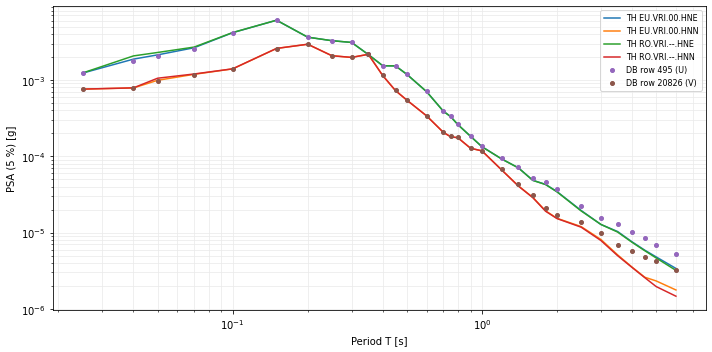

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for lab, p in psa.items():
    ax.plot(periods, p, lw=1.5, label=f"TH {lab}")
for i, r in db_rows.iterrows():
    ax.plot(periods, r[list(periods)].to_numpy(float), "o", ms=4, label=f"DB row {i} ({r['component']})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Period T [s]"); ax.set_ylabel("PSA (5 %) [g]")
ax.grid(True, which="both", color="0.92"); ax.legend(fontsize=8)
fig.tight_layout()

## 5. What the new converter does with this file

In [7]:
from phd_project.scripts.data_handling.convert_esm_records_to_json import (
    select_component_dataset, _location_from_filename)

for comp in ("U", "V"):
    try:
        ds, net, loc, cha = select_component_dataset(h5, STATION, comp, _location_from_filename(FP))
        print(comp, "->", net, repr(loc), cha)
    except ValueError as exc:
        print(comp, "-> fails:", exc)

U -> fails: 2 instruments at location '00': [('EU', '00', 'HN'), ('RO', '', 'HN')]; cannot tell which one the DB record is
V -> fails: 2 instruments at location '00': [('EU', '00', 'HN'), ('RO', '', 'HN')]; cannot tell which one the DB record is


## 6. Double-network files (GE / HL)

Seven files were listed (one of them, `EMSC-20131012_0000044__KTHA__00.h5`, twice), giving six unique files. They
are the recordings behind the "ambiguous tags" of nb 043 §2. Questions:
* what does each file look like?
* do they have VRI's double-network characteristic?
* why can't their records be resolved?

In [8]:
from IPython.display import Markdown, display

GEHL_FILES = [
    "EMSC-20131012_0000044__KTHA__00.h5", "EMSC-20150416_0000081__IMMV__00.h5",
    "EMSC-20140126_0000085__KTHA__00.h5", "EMSC-20131012_0000044__IMMV__00.h5",
    "EMSC-20130615_0000050__IMMV__00.h5", "EMSC-20131012_0000044__KTHA__00.h5",   # listed twice
    "EMSC-20140126_0000046__IMMV__00.h5",
]
GEHL_FILES = list(dict.fromkeys(GEHL_FILES))          # drop the duplicate, keep the order
SRC = Path(cfg["raw_data"]["esm_hdf5_folder"])


def markdown_tree(fp):
    """The header-style tree of one ESM HDF5 file, as a markdown code block (read-only)."""
    lines = [f"### `{fp.name}`", "", "```"]
    with h5py.File(fp, "r") as f:
        fa = {k: v.decode() if isinstance(v, bytes) else v for k, v in f.attrs.items()}
        lines.append(f"/                          attrs: {fa}")
        tops = list(f)
        for i, top in enumerate(tops):
            last_top = i == len(tops) - 1
            lines.append(f"{'└──' if last_top else '├──'} {top}/" + ("" if len(f[top]) else "         empty"))
            if top != "Waveforms":
                continue
            groups = list(f[top])
            for j, g in enumerate(groups):
                last_g = j == len(groups) - 1
                net, sta = g.split(".", 1)
                pre = "    " if last_top else "│   "
                lines.append(f"{pre}{'└──' if last_g else '├──'} {g}/   network {net}, station {sta}")
                keys = sorted(f[top][g])
                for k_i, k in enumerate(keys):
                    ds = f[top][g][k]
                    seed, start, end = k.split("__")[:3]
                    loc = seed.split(".")[2]
                    pre2 = pre + ("    " if last_g else "│   ")
                    lines.append(f"{pre2}{'└──' if k_i == len(keys) - 1 else '├──'} {seed}  "
                                 f"loc={loc!r:<5} {start} → {end}  {ds.shape}  "
                                 f"{float(ds.attrs['sampling_rate']):g} Hz")
    lines.append("```")
    return "\n".join(lines)


for name in GEHL_FILES:
    display(Markdown(markdown_tree(SRC / name)))

### `EMSC-20131012_0000044__KTHA__00.h5`

```
/                          attrs: {'file_format': 'ASDF', 'file_format_version': '1.0.3'}
├── AuxiliaryData/         empty
├── Provenance/         empty
└── Waveforms/
    ├── GE.KTHA/   network GE, station KTHA
    │   ├── GE.KTHA..HNE  loc=''    2013-10-12T13:11:05 → 2013-10-12T13:15:54  (57930,)  200 Hz
    │   ├── GE.KTHA..HNN  loc=''    2013-10-12T13:11:05 → 2013-10-12T13:15:54  (57930,)  200 Hz
    │   └── GE.KTHA..HNZ  loc=''    2013-10-12T13:11:05 → 2013-10-12T13:15:54  (57930,)  200 Hz
    └── HL.KTHA/   network HL, station KTHA
        ├── HL.KTHA..HNE  loc=''    2013-10-12T13:11:05 → 2013-10-12T13:16:00  (59134,)  200 Hz
        ├── HL.KTHA..HNN  loc=''    2013-10-12T13:11:05 → 2013-10-12T13:16:00  (59134,)  200 Hz
        └── HL.KTHA..HNZ  loc=''    2013-10-12T13:11:05 → 2013-10-12T13:16:00  (59134,)  200 Hz
```

### `EMSC-20150416_0000081__IMMV__00.h5`

```
/                          attrs: {'file_format': 'ASDF', 'file_format_version': '1.0.3'}
├── AuxiliaryData/         empty
├── Provenance/         empty
└── Waveforms/
    ├── GE.IMMV/   network GE, station IMMV
    │   ├── GE.IMMV..HNE  loc=''    2015-04-16T18:07:32 → 2015-04-16T18:12:50  (63664,)  200 Hz
    │   ├── GE.IMMV..HNN  loc=''    2015-04-16T18:07:32 → 2015-04-16T18:12:50  (63664,)  200 Hz
    │   └── GE.IMMV..HNZ  loc=''    2015-04-16T18:07:32 → 2015-04-16T18:12:50  (63664,)  200 Hz
    └── HL.IMMV/   network HL, station IMMV
        ├── HL.IMMV..HNE  loc=''    2015-04-16T18:07:32 → 2015-04-16T18:12:50  (63664,)  200 Hz
        ├── HL.IMMV..HNN  loc=''    2015-04-16T18:07:32 → 2015-04-16T18:12:50  (63664,)  200 Hz
        └── HL.IMMV..HNZ  loc=''    2015-04-16T18:07:32 → 2015-04-16T18:12:50  (63664,)  200 Hz
```

### `EMSC-20140126_0000085__KTHA__00.h5`

```
/                          attrs: {'file_format': 'ASDF', 'file_format_version': '1.0.3'}
├── AuxiliaryData/         empty
├── Provenance/         empty
└── Waveforms/
    ├── GE.KTHA/   network GE, station KTHA
    │   ├── GE.KTHA..HNE  loc=''    2014-01-26T18:45:37 → 2014-01-26T18:49:14  (43490,)  200 Hz
    │   ├── GE.KTHA..HNN  loc=''    2014-01-26T18:45:37 → 2014-01-26T18:49:14  (43490,)  200 Hz
    │   └── GE.KTHA..HNZ  loc=''    2014-01-26T18:45:37 → 2014-01-26T18:49:14  (43490,)  200 Hz
    └── HL.KTHA/   network HL, station KTHA
        ├── HL.KTHA..HNE  loc=''    2014-01-26T18:45:37 → 2014-01-26T18:49:14  (43490,)  200 Hz
        ├── HL.KTHA..HNN  loc=''    2014-01-26T18:45:37 → 2014-01-26T18:49:14  (43490,)  200 Hz
        └── HL.KTHA..HNZ  loc=''    2014-01-26T18:45:37 → 2014-01-26T18:49:14  (43490,)  200 Hz
```

### `EMSC-20131012_0000044__IMMV__00.h5`

```
/                          attrs: {'file_format': 'ASDF', 'file_format_version': '1.0.3'}
├── AuxiliaryData/         empty
├── Provenance/         empty
└── Waveforms/
    ├── GE.IMMV/   network GE, station IMMV
    │   ├── GE.IMMV..HNE  loc=''    2013-10-12T13:11:00 → 2013-10-12T13:15:45  (56948,)  200 Hz
    │   ├── GE.IMMV..HNN  loc=''    2013-10-12T13:11:00 → 2013-10-12T13:15:45  (56948,)  200 Hz
    │   └── GE.IMMV..HNZ  loc=''    2013-10-12T13:11:00 → 2013-10-12T13:15:45  (56948,)  200 Hz
    └── HL.IMMV/   network HL, station IMMV
        ├── HL.IMMV..HNE  loc=''    2013-10-12T13:11:20 → 2013-10-12T13:13:50  (29988,)  200 Hz
        ├── HL.IMMV..HNN  loc=''    2013-10-12T13:11:20 → 2013-10-12T13:13:50  (29988,)  200 Hz
        └── HL.IMMV..HNZ  loc=''    2013-10-12T13:11:20 → 2013-10-12T13:13:50  (29988,)  200 Hz
```

### `EMSC-20130615_0000050__IMMV__00.h5`

```
/                          attrs: {'file_format': 'ASDF', 'file_format_version': '1.0.3'}
├── AuxiliaryData/         empty
├── Provenance/         empty
└── Waveforms/
    ├── GE.IMMV/   network GE, station IMMV
    │   ├── GE.IMMV..HNE  loc=''    2013-06-15T16:10:57 → 2013-06-15T16:14:27  (42130,)  200 Hz
    │   ├── GE.IMMV..HNN  loc=''    2013-06-15T16:10:57 → 2013-06-15T16:14:27  (42130,)  200 Hz
    │   └── GE.IMMV..HNZ  loc=''    2013-06-15T16:10:57 → 2013-06-15T16:14:27  (42130,)  200 Hz
    └── HL.IMMV/   network HL, station IMMV
        ├── HL.IMMV..HNE  loc=''    2013-06-15T16:10:57 → 2013-06-15T16:14:27  (42130,)  200 Hz
        ├── HL.IMMV..HNN  loc=''    2013-06-15T16:10:57 → 2013-06-15T16:14:27  (42130,)  200 Hz
        └── HL.IMMV..HNZ  loc=''    2013-06-15T16:10:57 → 2013-06-15T16:14:27  (42130,)  200 Hz
```

### `EMSC-20140126_0000046__IMMV__00.h5`

```
/                          attrs: {'file_format': 'ASDF', 'file_format_version': '1.0.3'}
├── AuxiliaryData/         empty
├── Provenance/         empty
└── Waveforms/
    ├── GE.IMMV/   network GE, station IMMV
    │   ├── GE.IMMV..HNE  loc=''    2014-01-26T13:56:35 → 2014-01-26T14:00:48  (50534,)  200 Hz
    │   ├── GE.IMMV..HNN  loc=''    2014-01-26T13:56:35 → 2014-01-26T14:00:48  (50534,)  200 Hz
    │   └── GE.IMMV..HNZ  loc=''    2014-01-26T13:56:35 → 2014-01-26T14:00:48  (50534,)  200 Hz
    └── HL.IMMV/   network HL, station IMMV
        ├── HL.IMMV..HNE  loc=''    2014-01-26T13:56:31 → 2014-01-26T14:00:57  (53248,)  200 Hz
        ├── HL.IMMV..HNN  loc=''    2014-01-26T13:56:31 → 2014-01-26T14:00:57  (53248,)  200 Hz
        └── HL.IMMV..HNZ  loc=''    2014-01-26T13:56:31 → 2014-01-26T14:00:57  (53248,)  200 Hz
```

### What the ESM flatfile says

`ESM_flatfile_SA.csv` (`cfg["raw_data"]["esm_flatfile"]`) still has the network and location code of each record. The
rows for these recordings are shown next to the station groups found in each HDF5 file. VRI is included as the
contrast case.

In [9]:
ff = pd.read_csv(cfg["raw_data"]["esm_flatfile"], sep=";", dtype=str,
                 usecols=["event_id", "network_code", "station_code", "location_code", "instrument_code"])

pairs = [tuple(n[:-3].split("__")[:2]) for n in GEHL_FILES] + [("EMSC-20100930_0000013", "VRI")]
rows = []
for ev, sta in pairs:
    hit = ff[(ff["event_id"] == ev) & (ff["station_code"] == sta)]
    with h5py.File(SRC / f"{ev}__{sta}__00.h5", "r") as f:
        groups = sorted(f["Waveforms"])
    rows.append({"event_id": ev, "station": sta,
                 "flatfile_networks": ", ".join(hit["network_code"] + "/" + hit["location_code"].fillna("")),
                 "n_flatfile_rows": len(hit),
                 "hdf5_station_groups": ", ".join(groups)})
pd.DataFrame(rows)

,event_id,station,flatfile_networks,n_flatfile_rows,hdf5_station_groups
0,EMSC-20131012_0000044,KTHA,"GE/00, HL/00",2,"GE.KTHA, HL.KTHA"
1,EMSC-20150416_0000081,IMMV,"GE/00, HL/00",2,"GE.IMMV, HL.IMMV"
2,EMSC-20140126_0000085,KTHA,"GE/00, HL/00",2,"GE.KTHA, HL.KTHA"
3,EMSC-20131012_0000044,IMMV,"GE/00, HL/00",2,"GE.IMMV, HL.IMMV"
4,EMSC-20130615_0000050,IMMV,"GE/00, HL/00",2,"GE.IMMV, HL.IMMV"
5,EMSC-20140126_0000046,IMMV,"GE/00, HL/00",2,"GE.IMMV, HL.IMMV"
6,EMSC-20100930_0000013,VRI,RO/00,1,"EU.VRI, RO.VRI"


### Which network did each DB row come from?

The combined selection DB dropped `network_code`, so for these recordings each tag has **two** DB rows per component.
Each DB row is scored (MSLE up to `max_usable_T`) against the matching channel of both networks (HNE for U, HNN for V).
If one network fits far better, that DB row came from that network.

In [10]:
out = []
for name in GEHL_FILES:
    ev, sta = name[:-3].split("__")[:2]
    psa_net = {}
    with h5py.File(SRC / name, "r") as f:
        for g in f["Waveforms"]:
            for k, ds in f["Waveforms"][g].items():
                cha = k.split("__")[0].split(".")[3]
                if cha in ("HNE", "HNN"):
                    acc = np.asarray(ds[()], float) / (100 * G0)
                    psa_net[(g.split(".")[0], cha)] = psa_spectrum(
                        acc, 1 / float(ds.attrs["sampling_rate"]), periods, 0.05)
    nets = sorted({n for n, _ in psa_net})
    for db_row, r in db[(db["event_id"] == ev) & (db["station_code"] == sta)].iterrows():
        cha = {"U": "HNE", "V": "HNN"}[r["component"]]
        m = tsv._usable_mask(periods, float(r["max_usable_T"]))
        sa = r[list(periods)].to_numpy(float)
        sc = {n: tsv._msle(psa_net[(n, cha)][m], sa[m]) for n in nets}
        best = min(sc, key=sc.get)
        out.append({"tag": r["tag"], "db_row": db_row, **{f"msle_{n}": sc[n] for n in nets},
                    "best_network": best,
                    "ratio_other_to_best": max(sc.values()) / min(sc.values())})
gehl = pd.DataFrame(out).set_index(["tag", "db_row"])
gehl.round(6)

msle_GE   msle_HL best_network  ratio_other_to_best
tag                             db_row                                                      
EMSC-20131012_0000044_KTHA_0__U 2249    0.000392  0.001216           GE             3.100446
                                2259    0.000408  0.000381           HL             1.068725
EMSC-20131012_0000044_KTHA_0__V 22580   0.000106  0.000607           GE             5.727039
                                22590   0.000461  0.000105           HL             4.377518
EMSC-20150416_0000081_IMMV_0__U 5448    0.000120  0.000120           GE             1.000000
                                5455    0.000120  0.000120           GE             1.000000
EMSC-20150416_0000081_IMMV_0__V 25779   0.000036  0.000036           GE             1.000000
                                25786   0.000036  0.000036           GE             1.000000
EMSC-20140126_0000085_KTHA_0__U 2627    0.000402  0.001019           GE             2.533452
                                2633    0.000626  0.000402           HL             1.555245
EMSC-20140126_0000085_KTHA_0__V 22958   0.000033  0.000510           GE            15.578223
                                22964   0.000396  0.000033           HL            12.085522
EMSC-20131012_0000044_IMMV_0__U 2247    0.000816  0.000826           GE             1.012745
                                2256    0.000795  0.000805           GE             1.012938
EMSC-20131012_0000044_IMMV_0__V 22578   0.000592  0.000584           HL             1.013598
                                22587   0.000599  0.000591           HL             1.013536
EMSC-20130615_0000050_IMMV_0__U 1868    0.000926  0.001748           GE             1.888877
                                1873    0.000943  0.000926           HL             1.019224
EMSC-20130615_0000050_IMMV_0__V 22199   0.000051  0.000637           GE            12.522633
                                22204   0.000305  0.000051           HL             6.007848
EMSC-20140126_0000046_IMMV_0__U 2576    0.000102  0.000664           GE             6.510809
                                2582    0.000380  0.000102           HL             3.728727
EMSC-20140126_0000046_IMMV_0__V 22907   0.000039  0.000500           GE            12.798363
                                22913   0.000418  0.000039           HL            10.696337

### The pattern

* **Yes: all six files have the double-network characteristic, in a different form from VRI.** Each holds the same
  station under two networks, `GE.<STA>` and `HL.<STA>`, both with a **blank** location code and HNE/HNN/HNZ at
  200 Hz. Sometimes the two windows are identical; sometimes they differ in start or length.
* **Unlike VRI, the ESM flatfile has a record for both networks** (GE and HL, each listed as location `00`). So these
  are two genuine DB records per component. VRI had only one (RO) in the flatfile, and its file's second network (EU)
  was an extra copy.
* **Why they are ambiguous:** the combined selection DB dropped `network_code` and set every location to `00`, so both
  records collapse onto one tag, `{event}_{station}_0__{comp}`, which gives two DB rows. In the HDF5 file both networks
  have location `""` = `00`, so the file-name location cannot tell them apart either, and the new converter fails with
  "2 instruments at location '00'". Only the **network code**, which the flatfile has and the combined DB lost, can say
  which one a selected record is. The table above shows which network each DB row matches.

In [11]:
# h5.close()   # when done